In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import json
import time

books = []

base_url = "https://books.toscrape.com/catalogue/"

rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

for page in range(1, 26):

    url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")

    all_books = soup.find_all("article", class_="product_pod")

    for book in all_books:

        title = book.h3.a["title"]

        price = book.find("p", class_="price_color").text.replace("£", "").replace("Â", "")

        availability = book.find("p", class_="instock availability").text.strip()

        rating = book.find("p")["class"][1]

        product_link = base_url + book.h3.a["href"].replace("../../../", "")

        # Visit each product page
        product_page = requests.get(product_link)
        product_soup = BeautifulSoup(product_page.text, "html.parser")

        # Description
        description = ""

        desc = product_soup.find("meta", attrs={"name": "description"})
        if desc:
            description = desc["content"].strip()

        # Product information
        table = product_soup.find("table")

        data = {}

        for row in table.find_all("tr"):
            key = row.th.text
            value = row.td.text
            data[key] = value

        # Category
        category = product_soup.find_all("a")[3].text

        books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "Product_URL": product_link,
            "Category": category,
            "Description": description,
            "UPC": data.get("UPC", ""),
            "Product_Type": data.get("Product Type", "")
        })

    #print("Page", page, "completed")

    time.sleep(1)

print("Total Books Extracted:", len(books))

Total Books: 500


In [2]:
# Save data into JSON

with open("books_data.json", "w", encoding="utf-8") as file:
    json.dump(books, file, indent=4)

print("JSON file saved")

# Read JSON

with open("books_data.json", "r", encoding="utf-8") as file:
    data = json.load(file)

# Convert into DataFrame

df = pd.DataFrame(data)

print(df.head())

print("\nShape of dataset:", df.shape)

JSON file saved
                                   Title  Price Rating Availability  \
0                   A Light in the Attic  51.77  Three     In stock   
1                     Tipping the Velvet  53.74    One     In stock   
2                             Soumission  50.10    One     In stock   
3                          Sharp Objects  47.82   Four     In stock   
4  Sapiens: A Brief History of Humankind  54.23   Five     In stock   

                                         Product_URL            Category  \
0  https://books.toscrape.com/catalogue/a-light-i...              Poetry   
1  https://books.toscrape.com/catalogue/tipping-t...  Historical Fiction   
2  https://books.toscrape.com/catalogue/soumissio...             Fiction   
3  https://books.toscrape.com/catalogue/sharp-obj...             Mystery   
4  https://books.toscrape.com/catalogue/sapiens-a...             History   

                                         Description               UPC  \
0  It's hard to imagine a 

In [3]:
from sklearn.preprocessing import MinMaxScaler

# Remove duplicates

df.drop_duplicates(inplace=True)

# Handle missing values

df.fillna("Unknown", inplace=True)

# Clean text

df["Title"] = df["Title"].str.strip()

df["Category"] = df["Category"].str.strip()

df["Description"] = df["Description"].str.strip()

# Convert price into float

df["Price"] = df["Price"].astype(float)

# Convert ratings into numbers

rating_dict = {
    "One":1,
    "Two":2,
    "Three":3,
    "Four":4,
    "Five":5
}

df["Rating"] = df["Rating"].map(rating_dict)

# New Feature 1

df["Title_Length"] = df["Title"].apply(len)

# New Feature 2

df["Availability_Status"] = df["Availability"].apply(lambda x: 1 if "In stock" in x else 0)

# New Feature 3

df["Price_per_Rating"] = df["Price"] / df["Rating"]

# New Feature 4

df["Price_Category"] = pd.cut(
    df["Price"],
    bins=[0,20,35,60],
    labels=["Low","Medium","High"]
)

# Min Max Normalization

scaler = MinMaxScaler()

df["Normalized_Price"] = scaler.fit_transform(df[["Price"]])

print(df.head())

print("\nData Types\n")
print(df.dtypes)

                                   Title  Price  Rating Availability  \
0                   A Light in the Attic  51.77       3     In stock   
1                     Tipping the Velvet  53.74       1     In stock   
2                             Soumission  50.10       1     In stock   
3                          Sharp Objects  47.82       4     In stock   
4  Sapiens: A Brief History of Humankind  54.23       5     In stock   

                                         Product_URL            Category  \
0  https://books.toscrape.com/catalogue/a-light-i...              Poetry   
1  https://books.toscrape.com/catalogue/tipping-t...  Historical Fiction   
2  https://books.toscrape.com/catalogue/soumissio...             Fiction   
3  https://books.toscrape.com/catalogue/sharp-obj...             Mystery   
4  https://books.toscrape.com/catalogue/sapiens-a...             History   

                                         Description               UPC  \
0  It's hard to imagine a world with

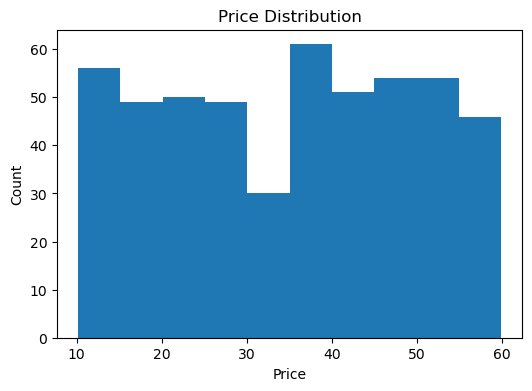

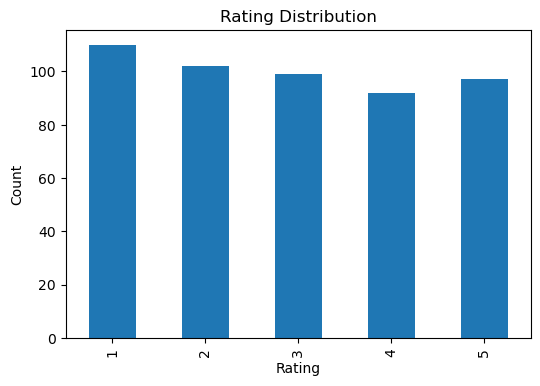

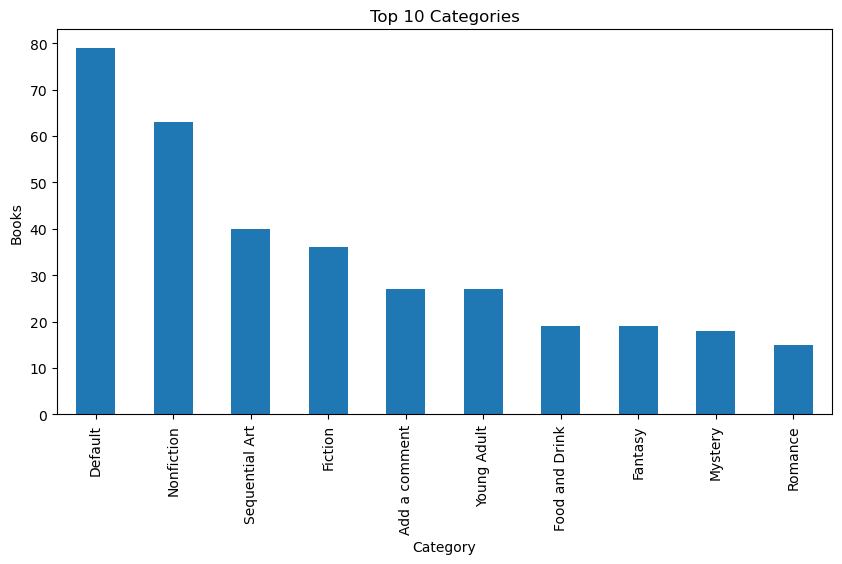

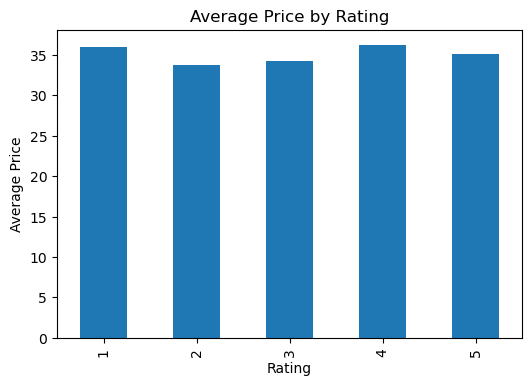

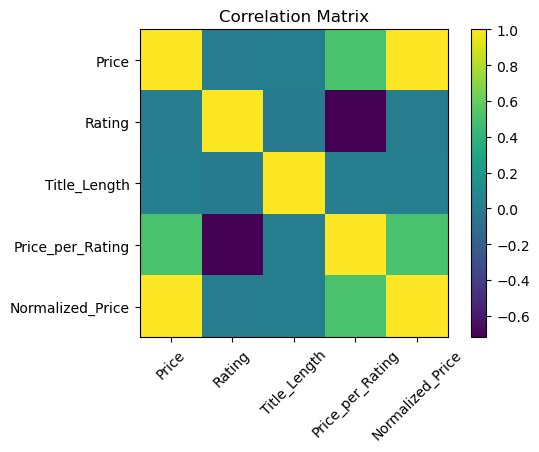

In [4]:
import matplotlib.pyplot as plt

# 1 Price Distribution

plt.figure(figsize=(6,4))
plt.hist(df["Price"], bins=10)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

# 2 Rating Distribution

plt.figure(figsize=(6,4))
df["Rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

# 3 Category Wise Books

plt.figure(figsize=(10,5))
df["Category"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Books")
plt.show()

# 4 Average Price by Rating

plt.figure(figsize=(6,4))
df.groupby("Rating")["Price"].mean().plot(kind="bar")
plt.title("Average Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price")
plt.show()

# 5 Correlation Heatmap

plt.figure(figsize=(6,4))

corr = df[
    ["Price",
     "Rating",
     "Title_Length",
     "Price_per_Rating",
     "Normalized_Price"]
].corr()

plt.imshow(corr)

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)

plt.yticks(range(len(corr.columns)), corr.columns)

plt.colorbar()

plt.title("Correlation Matrix")

plt.show()

In [5]:
# Save cleaned dataset

df.to_csv("books_dataset_cleaned.csv", index=False)

print("CSV file saved successfully")

print("\nDataset Shape:", df.shape)

print("\nBusiness Insights\n")

print("1. Total number of books:", len(df))

print("2. Average book price:", round(df["Price"].mean(),2))

print("3. Most common rating:")
print(df["Rating"].value_counts().idxmax())

print("4. Category with maximum books:")
print(df["Category"].value_counts().idxmax())

print("5. Highest priced book:")
print(df.loc[df["Price"].idxmax(),["Title","Price"]])

print("\nMin-Max Normalization Justification")
print("Price values have different ranges. Min-Max normalization scales prices between 0 and 1, making them suitable for machine learning algorithms and easier comparison with other numerical features.")



CSV file saved successfully

Dataset Shape: (500, 14)

Business Insights

1. Total number of books: 500
2. Average book price: 35.04
3. Most common rating:
1
4. Category with maximum books:
Default
5. Highest priced book:
Title    The Diary of a Young Girl
Price                         59.9
Name: 366, dtype: object

Min-Max Normalization Justification
Price values have different ranges. Min-Max normalization scales prices between 0 and 1, making them suitable for machine learning algorithms and easier comparison with other numerical features.
